# MLIC / MLIC++ on Kodak

In [1]:
!pip -q install --no-deps compressai
!pip -q install torch-geometric timm einops pytorch-msssim gdown
!git clone -q https://github.com/JiangWeibeta/MLIC.git /content/MLIC && git -C /content/MLIC checkout -q 4aa9d2a
!printf '[project]\nname="mlicpp"\nversion="0"\n[tool.setuptools.packages.find]\ninclude=["models*","modules*","utils*","config*","loss*"]\n' > /content/MLIC/MLIC++/pyproject.toml
!pip -q install --no-deps /content/MLIC/MLIC++

import random
import numpy as np
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device, torch.cuda.get_device_name(0))

torch.manual_seed(1984)
random.seed(1984)
np.random.seed(1984)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
compressai 1.2.8 requires pybind11>=2.6.0, which is not installed.
compressai 1.2.8 requires tomli>=2.2.1, which is not installed.
compressai 1.2.8 requires numpy<2.0,>=1.21.0, but you have numpy 2.4.6 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
cuda Tesla T4


In [2]:
import os, json, urllib.request
import requests
import gdown

os.makedirs("data/test", exist_ok=True)
for i in range(1, 25):
    urllib.request.urlretrieve(f"https://r0k.us/graphics/kodak/kodak/kodim{i:02d}.png", f"data/test/kodim{i:02d}.png")

!test -d data/train || (wget -q https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip && unzip -q DIV2K_train_HR.zip && mv DIV2K_train_HR data/train)

CKPTS = {
    0.0018: "1rRdM5X5ueWvW5-ZN3gwPoXGECvgIcz-2",
    0.0035: "1SlIsurg4JocEBAWrnp1jiEe1EnFgw5AP",
    0.0067: "1CKpyUXwifJZ9gb0l_Di6R-TMH9f4UmAU",
    0.0130: "1Qp4YBea3GkLSGDyYgo7OeaWZa5_rX8kJ",
    0.0250: "1krGCTYat0Qkcp0QPaNC5sP3ofrq-eQsv",
    0.0483: "1mIDwO_2Q1sNVriCFiLS1oxgfbVUaHihl",
}
os.makedirs("ckpt", exist_ok=True)
for lmbda, fid in CKPTS.items():
    if not os.path.exists(f"ckpt/{lmbda}.pth.tar"):
        gdown.download(id=fid, output=f"ckpt/{lmbda}.pth.tar")

REF = {name: json.load(open(f"/content/MLIC/results/kodak/{f}.json"))
       for name, f in [("MLIC", "mlic_mse"), ("MLIC+", "mlicplus_mse"), ("MLIC++", "mlicplusplus_mse")]}
vtm = requests.get("https://raw.githubusercontent.com/InterDigitalInc/CompressAI/3698ce7/results/image/kodak/vtm.json").json()["results"]
REF["VTM"] = {"bpp": vtm["bpp"], "psnr": vtm["psnr-rgb"]}

Downloading...
From (original): https://drive.google.com/uc?id=1rRdM5X5ueWvW5-ZN3gwPoXGECvgIcz-2
From (redirected): https://drive.google.com/uc?id=1rRdM5X5ueWvW5-ZN3gwPoXGECvgIcz-2&confirm=t&uuid=95981779-ea65-4472-9a14-21379509805e
To: /content/ckpt/0.0018.pth.tar
100%|██████████| 1.40G/1.40G [00:20<00:00, 67.1MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1SlIsurg4JocEBAWrnp1jiEe1EnFgw5AP
From (redirected): https://drive.google.com/uc?id=1SlIsurg4JocEBAWrnp1jiEe1EnFgw5AP&confirm=t&uuid=29eea66f-c3d9-4004-9a26-d23173385cdf
To: /content/ckpt/0.0035.pth.tar
100%|██████████| 1.40G/1.40G [00:24<00:00, 57.4MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1CKpyUXwifJZ9gb0l_Di6R-TMH9f4UmAU
From (redirected): https://drive.google.com/uc?id=1CKpyUXwifJZ9gb0l_Di6R-TMH9f4UmAU&confirm=t&uuid=4e24a509-8be5-4b63-b32a-1b580f13a51d
To: /content/ckpt/0.0067.pth.tar
100%|██████████| 1.40G/1.40G [00:27<00:00, 51.5MB/s]
Downloading...
From (original): https://dri

In [7]:
import logging
from types import SimpleNamespace
from tqdm.auto import tqdm, trange
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter
from torchvision import transforms
from transformers import get_linear_schedule_with_warmup
from compressai.datasets import ImageFolder
import compressai.ops
compressai.ops.ste_round = compressai.ops.quantize_ste
from models import MLICPlusPlus
from config.config import model_config
from loss.rd_loss import RateDistortionLoss
from utils.optimizers import configure_optimizers
from utils.training import warmup_one_epoch
from utils.testing import test_one_epoch
from utils.logger import setup_logger


class TqdmLoader(DataLoader):
    def __iter__(self):
        return iter(tqdm(super().__iter__(), total=len(self), leave=False))


def train(lmbda, epochs, batch_size, name):
    os.makedirs(f"logs/{name}", exist_ok=True)
    for split in ("train", "val"):
        if not logging.getLogger(split).handlers:
            setup_logger(split, f"logs/{name}", f"{split}_{name}", level=logging.INFO, screen=True, tofile=True)
            logging.getLogger(split).propagate = False

    train_dl = TqdmLoader(ImageFolder("data", split="train", transform=transforms.Compose([transforms.RandomCrop(256), transforms.ToTensor()])),
                          batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
    test_dl = DataLoader(ImageFolder("data", split="test", transform=transforms.ToTensor()), batch_size=1)

    net = MLICPlusPlus(config=model_config()).to(device)
    optimizer, aux_optimizer = configure_optimizers(net, SimpleNamespace(learning_rate=1e-4, aux_learning_rate=1e-3))
    lr_scheduler = get_linear_schedule_with_warmup(optimizer, len(train_dl), len(train_dl) * 150)
    criterion = RateDistortionLoss(lmbda=lmbda, metrics="mse")
    tb = SummaryWriter(f"tb/{name}")

    step, best = 0, float("inf")
    for epoch in trange(epochs):
        step = warmup_one_epoch(net, criterion, train_dl, optimizer, aux_optimizer, epoch, 1.0,
                                logging.getLogger("train"), tb, step, lr_scheduler)
        loss = test_one_epoch(epoch, test_dl, net, criterion, f"val/{name}", logging.getLogger("val"), tb)
        if loss < best:
            best = loss
            net.update(force=True)
            torch.save({"epoch": epoch + 1, "state_dict": net.state_dict()}, f"ckpt/{name}.pth.tar")

In [5]:
import pandas as pd
import torch.nn.functional as F
import models.mlicpp as mlicpp
from modules.transform import SynthesisTransform, SynthesisTransformOld, LatentResidualPrediction, LatentResidualPredictionOld
from utils.testing import compress_one_image, decompress_one_image
from utils.utils import torch2img
from utils.metrics import compute_metrics


def load(path, old):
    mlicpp.SynthesisTransform = SynthesisTransformOld if old else SynthesisTransform
    mlicpp.LatentResidualPrediction = LatentResidualPredictionOld if old else LatentResidualPrediction
    net = MLICPlusPlus(config=model_config()).to(device).eval()
    net.load_state_dict(torch.load(path, map_location=device, weights_only=False)["state_dict"])
    return net


@torch.no_grad()
def evaluate(net, dl, stream_dir="stream"):
    os.makedirs(stream_dir, exist_ok=True)
    rows = []
    for i, x in enumerate(dl):
        x = x.to(device)
        H, W = x.shape[2:]
        x_pad = F.pad(x, (0, -W % 64, 0, -H % 64))
        net.update_resolutions(16, 16)
        bpp, _ = compress_one_image(net, x_pad, stream_dir, H, W, str(i))
        net.update_resolutions(16, 16)
        x_hat, _ = decompress_one_image(net, stream_dir, str(i))
        psnr, ms_ssim = compute_metrics(torch2img(x_hat), torch2img(x))
        rows.append({"bpp": bpp, "psnr": psnr, "ms_ssim": ms_ssim})
    return pd.DataFrame(rows).mean().to_dict()


def bd_rate(r1, d1, r2, d2):
    p1, p2 = np.polyfit(d1, np.log(r1), 3), np.polyfit(d2, np.log(r2), 3)
    lo, hi = max(min(d1), min(d2)), min(max(d1), max(d2))
    i1, i2 = (np.polyval(np.polyint(p), hi) - np.polyval(np.polyint(p), lo) for p in (p1, p2))
    return (np.exp((i2 - i1) / (hi - lo)) - 1) * 100

In [8]:
train(lmbda=0.0483, epochs=40, batch_size=8, name="short_0.0483")

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

26-11-17 19:41:29.458 - INFO: Train epoch 0: [    0/800 (0%)] Lr: 0.000001 | Loss: 757.9555 | MSE loss: 0.2411 | Bpp loss: 0.61 | Aux loss: 7918.08
26-11-17 19:43:47.466 - INFO: Test epoch 0: Average losses: Loss: 66.4543 | MSE loss: 0.020838 | Bpp loss: 1.0079 | Aux loss: 7898.10 | PSNR: 16.975906 | MS-SSIM: 0.593628


  0%|          | 0/100 [00:00<?, ?it/s]

26-11-17 19:43:53.280 - INFO: Train epoch 1: [    0/800 (0%)] Lr: 0.000100 | Loss: 110.4619 | MSE loss: 0.0348 | Bpp loss: 1.28 | Aux loss: 7897.81
26-11-17 19:46:11.597 - INFO: Test epoch 1: Average losses: Loss: 31.5466 | MSE loss: 0.009823 | Bpp loss: 0.6951 | Aux loss: 7856.22 | PSNR: 20.449255 | MS-SSIM: 0.695726


  0%|          | 0/100 [00:00<?, ?it/s]

... (71 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

26-11-17 21:12:34.189 - INFO: Train epoch 38: [    0/800 (0%)] Lr: 0.000100 | Loss: 5.9440 | MSE loss: 0.0016 | Bpp loss: 1.04 | Aux loss: 4402.51
26-11-17 21:14:56.483 - INFO: Test epoch 38: Average losses: Loss: 7.6841 | MSE loss: 0.002154 | Bpp loss: 0.9199 | Aux loss: 4254.53 | PSNR: 27.211951 | MS-SSIM: 0.947014


  0%|          | 0/100 [00:00<?, ?it/s]

26-11-17 21:15:01.219 - INFO: Train epoch 39: [    0/800 (0%)] Lr: 0.000100 | Loss: 18.6458 | MSE loss: 0.0055 | Bpp loss: 1.51 | Aux loss: 4253.28
26-11-17 21:17:21.174 - INFO: Test epoch 39: Average losses: Loss: 7.8353 | MSE loss: 0.002215 | Bpp loss: 0.8793 | Aux loss: 4085.75 | PSNR: 27.057306 | MS-SSIM: 0.946334


In [9]:
torch.backends.cudnn.deterministic = True
kodak = DataLoader(ImageFolder("data", split="test", transform=transforms.ToTensor()), batch_size=1)

rows = [{"model": "MLIC++ (official weights)", "lmbda": l, **evaluate(load(f"ckpt/{l}.pth.tar", old=True), kodak)} for l in CKPTS]
rows.append({"model": "MLIC++ (short run)", "lmbda": 0.0483, **evaluate(load("ckpt/short_0.0483.pth.tar", old=False), kodak)})
results = pd.DataFrame(rows)
results.to_csv("kodak_results.csv", index=False)
results.round(4)

,model,lmbda,bpp,psnr,ms_ssim
0,MLIC++ (official weights),0.0018,0.1075,29.1621,0.9278
1,MLIC++ (official weights),0.0035,0.1747,30.7163,0.9511
2,MLIC++ (official weights),0.0067,0.2721,32.3333,0.9673
3,MLIC++ (official weights),0.0130,0.4129,34.1677,0.9788
4,MLIC++ (official weights),0.0250,0.5923,35.8162,0.9857
5,MLIC++ (official weights),0.0483,0.8026,37.3219,0.9901
6,MLIC++ (short run),0.0483,0.9234,27.2120,0.9470


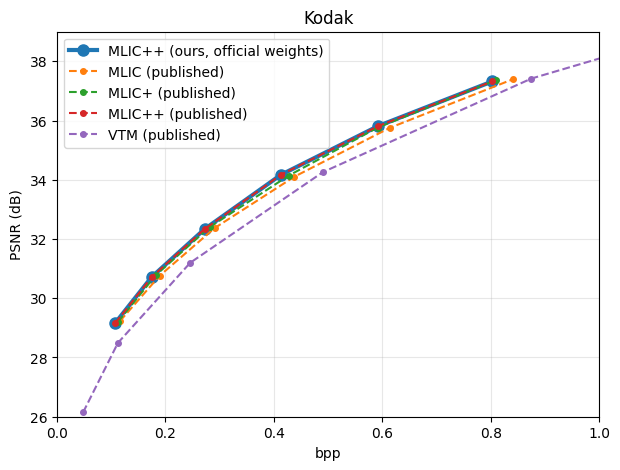

,BD-rate vs VTM (%)
MLIC (published),-9.91
MLIC+ (published),-13.19
MLIC++ (published),-15.14
MLIC++ (ours),-15.14


In [11]:
import matplotlib.pyplot as plt

ours = results[results.model == "MLIC++ (official weights)"]
short = results[results.model == "MLIC++ (short run)"]

plt.figure(figsize=(7, 5))
plt.plot(ours.bpp, ours.psnr, "-o", lw=3, ms=8, label="MLIC++ (ours, official weights)")
for name, r in REF.items():
    plt.plot(r["bpp"], r["psnr"], "--o", ms=4, label=f"{name} (published)")
# plt.plot(short.bpp, short.psnr, "*", ms=14, label="MLIC++ (ours, short run)")
plt.xlim(0, 1)
plt.ylim(26, 39)
plt.xlabel("bpp")
plt.ylabel("PSNR (dB)")
plt.title("Kodak")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("kodak_rd.png", dpi=300, bbox_inches="tight")
plt.show()

curves = {f"{n} (published)": r for n, r in REF.items() if n != "VTM"}
curves["MLIC++ (ours)"] = {"bpp": ours.bpp, "psnr": ours.psnr}
bd = pd.DataFrame({"BD-rate vs VTM (%)": {n: bd_rate(REF["VTM"]["bpp"], REF["VTM"]["psnr"], c["bpp"],
c["psnr"]) for n, c in curves.items()}})
bd.to_csv("kodak_bdrate.csv")
bd.round(2)